<a href="https://colab.research.google.com/github/Asmodey-it/machine-navchannya/blob/main/%D0%9B%D0%A06_%D0%9F%D0%B0%D0%BD%D1%87%D0%B5%D0%BA%D0%BD%D0%BE_%D0%9C_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [17]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [18]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [19]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [20]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [21]:
# TODO: підрахуйте частоти категорій у gender.
print("--- Gender frequencies ---")
print(df['gender'].value_counts())

--- Gender frequencies ---
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [22]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("\n--- Smoking history frequencies ---")
print(df['smoking_history'].value_counts())


--- Smoking history frequencies ---
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [23]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [24]:
# TODO: df.dtypes
print("Типи даних:")
display(df.dtypes)

Типи даних:


,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [25]:
# TODO: df['diabetes'].value_counts()
print("Баланс цільової змінної (diabetes):")
print(df['diabetes'].value_counts(normalize=True) * 100)
print(df['diabetes'].value_counts())

Баланс цільової змінної (diabetes):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64
diabetes
0    91500
1     8500
Name: count, dtype: int64


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [26]:
# TODO: df.isnull().sum()
print("Пропущені значення:")
print(df.isnull().sum())

Пропущені значення:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [27]:
# TODO: df.duplicated().sum()
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [28]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)
print("Кількість рядків після видалення дублікатів:", len(df))

Кількість рядків після видалення дублікатів: 96146


In [29]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [30]:
# TODO: df['diabetes'].value_counts()
print("Баланс після видалення дублікатів:")
print(df['diabetes'].value_counts())

Баланс після видалення дублікатів:
diabetes
0    87664
1     8482
Name: count, dtype: int64


Побудувати гістограму для цільової змінної


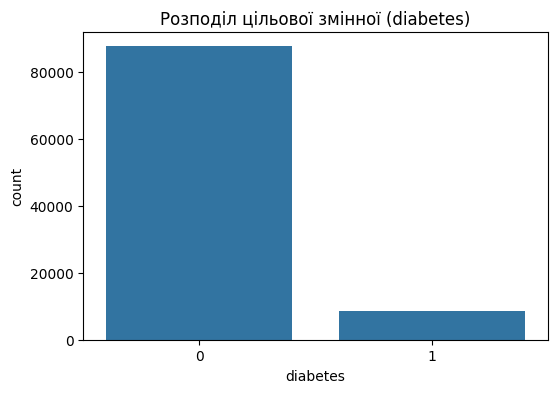

In [31]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл цільової змінної (diabetes)')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [14]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [32]:
# TODO: створіть X та y, де y — стовпець diabetes.
X = df.drop(columns=['diabetes'])
y = df['diabetes']
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Розмір X_train: {X_train.shape}, X_test: {X_test.shape}")

Розмір X_train: (76916, 8), X_test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [33]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Колонок після кодування:", X_train.shape[1])

Колонок після кодування: 13


In [34]:
# TODO: виведіть статистики опису X_train.
display(X_train.describe())

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [35]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_data = X_train.copy()
train_data['diabetes'] = y_train
correlation_with_target = train_data.corr()['diabetes'].sort_values(ascending=False)
print("Кореляція ознак із цільовою змінною (на train):")
print(correlation_with_target)

Кореляція ознак із цільовою змінною (на train):
diabetes                       1.000000
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


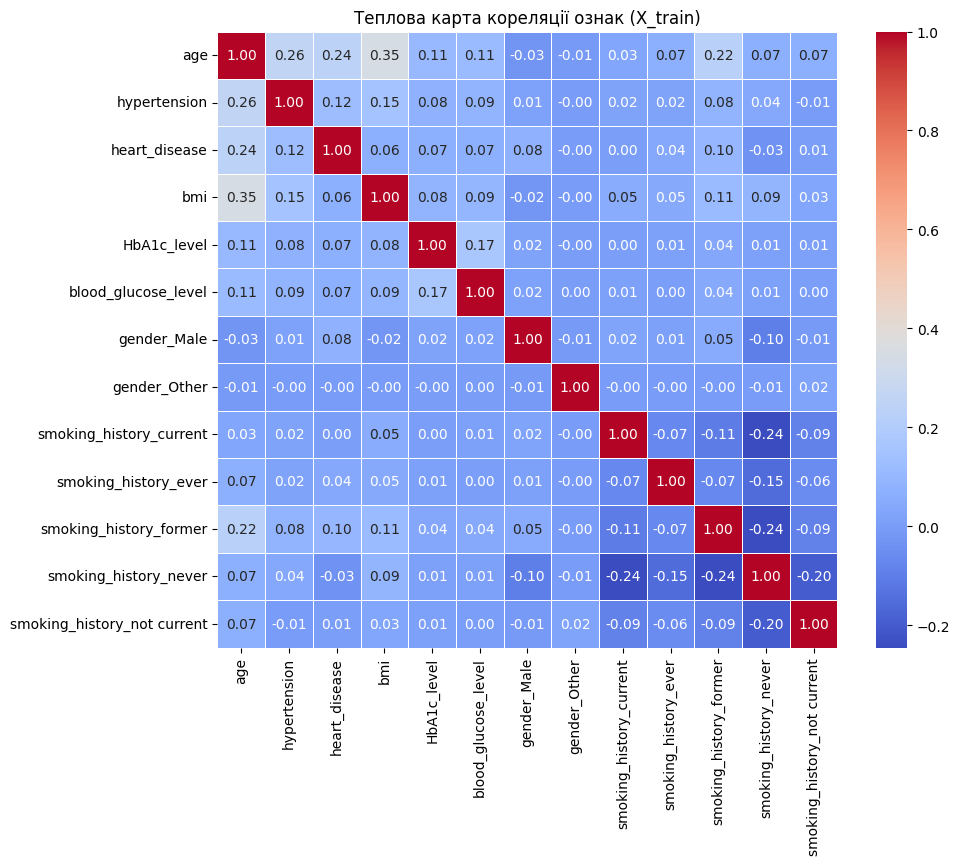

In [36]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
plt.figure(figsize=(10, 8))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Теплова карта кореляції ознак (X_train)')
plt.show()

**Висновок:** Найвищу кореляцію з діабетом мають рівняння blood_glucose_level та HbA1c_level. Мультиколінеарність між більшістю інших ознак помірна.

Перевірити викиди **лише на навчальній вибірці**

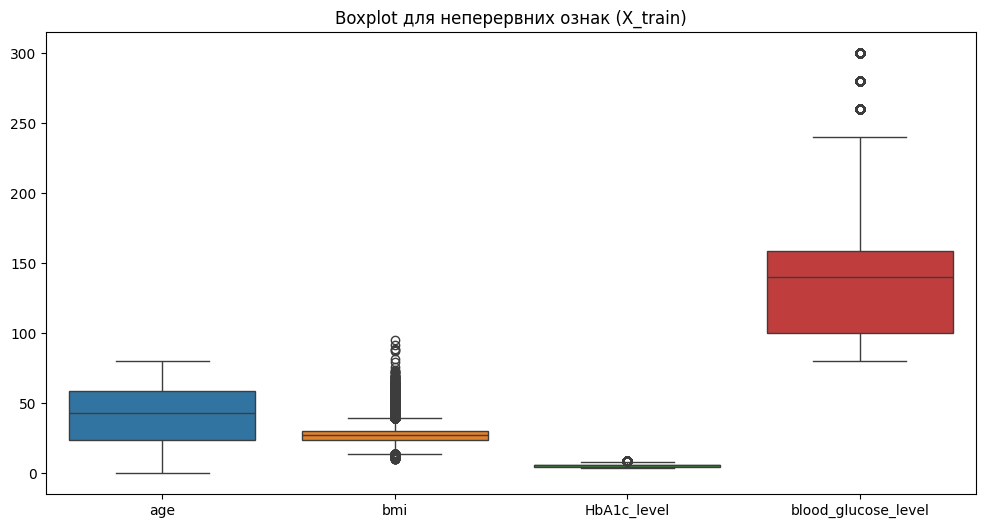

In [37]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Boxplot для неперервних ознак (X_train)')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [38]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print("Асиметрія (Skewness) для X_train:")
print(X_train[continuous_cols].skew())

Асиметрія (Skewness) для X_train:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [39]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [41]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [42]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
print("До SMOTE (y_train):")
print(pd.Series(y_train).value_counts())
print("\nПісля SMOTE (y_train_resampled):")
print(pd.Series(y_train_resampled).value_counts())

До SMOTE (y_train):
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE (y_train_resampled):
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [15]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Ridge Classifier': RidgeClassifier(random_state=42),
    'SGD Classifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: Logistic Regression
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



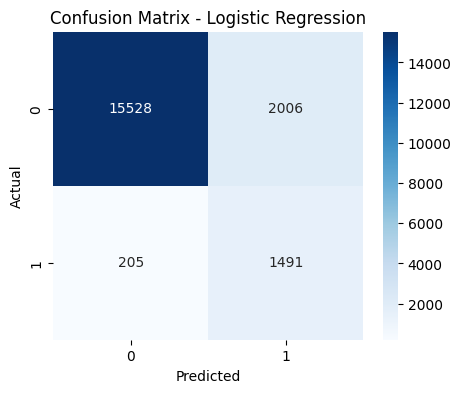


Модель: Ridge Classifier
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



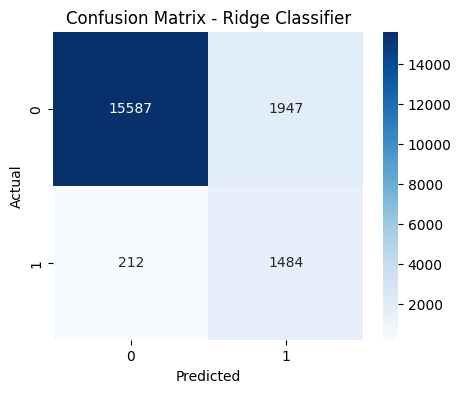


Модель: SGD Classifier
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



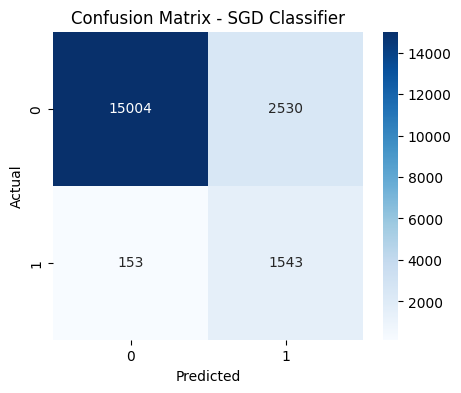


Модель: SVC
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



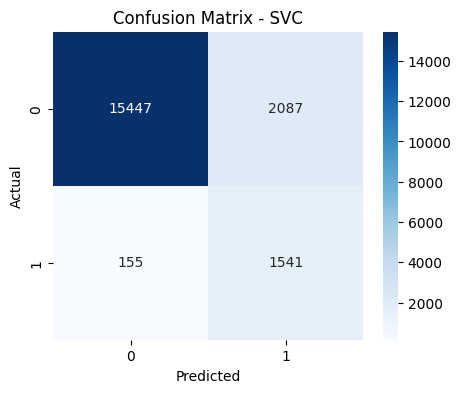

In [28]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
for name, model in models.items():
    print(f"\n{'='*30}\nМодель: {name}\n{'='*30}")
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

Оптимізувати гіперпараметри


In [1]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'Ridge Classifier': {'model__alpha': [0.1, 1.0, 10.0]},
    'SGD Classifier': {'model__alpha': [0.0001, 0.001, 0.01], 'model__loss': ['log_loss', 'hinge']},
    'SVC': {'model__C': [0.1, 1, 10], 'model__kernel': ['linear', 'rbf']}
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [2]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [43]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\n{'*'*10} Налаштування для: {name} {'*'*10}")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    # Видаляємо префікс 'model__' з параметрів для пайплайну, якщо потрібно, або залишаємо правильні ключі
    current_grid = param_grids[name]

    halving_cv = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=current_grid,
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    halving_cv.fit(X_train, y_train)

    best_models[name] = halving_cv.best_estimator_
    best_scores[name] = halving_cv.best_score_

    print(f"Оптимальні параметри: {halving_cv.best_params_}")
    print(f"Найкращий F1 на CV: {halving_cv.best_score_:.4f}")

    y_pred = halving_cv.predict(X_test)
    print("Classification Report на Test:")
    print(classification_report(y_test, y_pred))


********** Налаштування для: Logistic Regression **********
Оптимальні параметри: {'model__C': 0.01}
Найкращий F1 на CV: 0.6864
Classification Report на Test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


********** Налаштування для: Ridge Classifier **********
Оптимальні параметри: {'model__alpha': 10.0}
Найкращий F1 на CV: 0.6587
Classification Report на Test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


********** Налаштування 

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [44]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
print(f"Найкраща модель за крос-валідацією: {best_model_name}")
print(f"Середній F1-score на CV: {best_scores[best_model_name]:.4f}")

Найкраща модель за крос-валідацією: Logistic Regression
Середній F1-score на CV: 0.6864


In [45]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
sample_indices = X_test.sample(10, random_state=42).index
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

comparison_df = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': sample_y_true.values,
    'Передбачений клас': sample_y_pred
})

display(comparison_df)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 15.3 MB/s  0:00:06

Додаткова модель: XGBoost
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



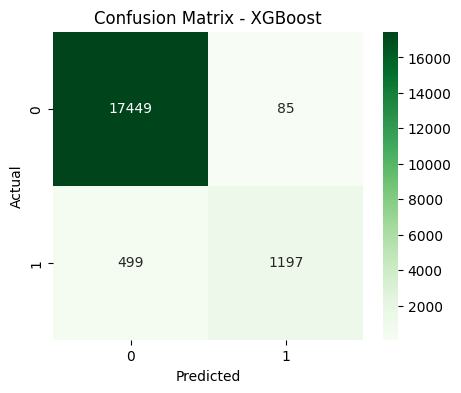


Додаткова модель: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



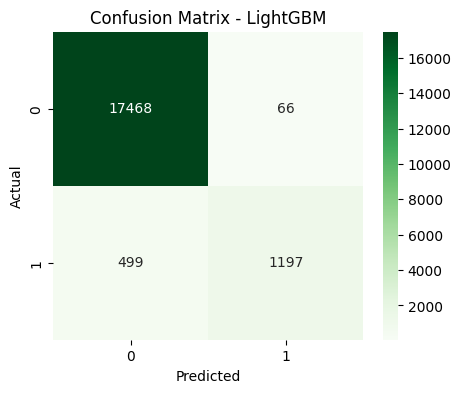


Додаткова модель: CatBoost
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



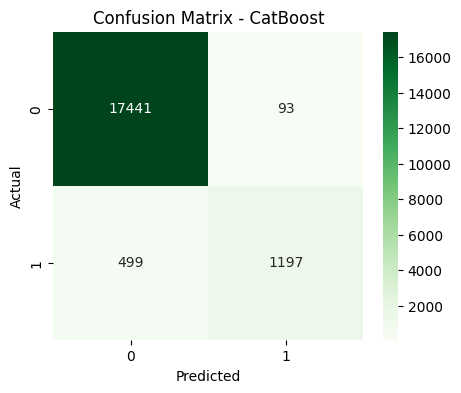

In [47]:
!pip install catboost xgboost lightgbm
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

for name, model in extra_models.items():
    print(f"\n{'='*30}\nДодаткова модель: {name}\n{'='*30}")

    # Використовуємо вже готові збалансовані та масштабовані дані
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()